# Fernandez et al., 2015 Forward Box Model
This Jupyter notebook aims to replicate the analysis and figures in Fernandez et al., 2015, "Ventilation time scales of the North Atlantic subtropical cell revealed by coral radiocarbon from the Cape Verde Islands." With replication, one can play with the forward model to recognize sensitivities that dictate the need for an inverse model. 

In [1]:
#Load packages and data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [2]:
#Functions translated from Matlab (to be transferred to .py file):

def Trend_Final(A, S):
    '''
    This function runs the forward model for Fernandez et al., 2015. Written originally in Matlab by Alvaro Fernandez, September 2014. 
    Modified as a function in Python by Brad Rosenheim, October 2026.

    The model uses the atmospheric Ku (vertical) and Ks (horizontal), previously calculated. To understand how these constants affect results, 
    the model perturbs their values by 25%. The model also varies the wind speed and mixed layer depth to understand how these affect results. 
    The variations happen along normal distributions, simultaneously, and independently. It is encouraged to run this function multiple times
    (n=1000 in the 2015 publication in Paleoclimatology) to summarize the cumulative effect of all variability in the model inputs. 

        Inputs:
            A (pandas DataFrame): This is the NH bomb curve D14C record on time
            S (pandas DataFrame): This is the sclerosponge record from the western subtropical Atlantic
        Outputs: 
            xi (np.array) - x-axis (time) interpolated to dx steps
            model_results (np.array) - radiocarbon values of the Cape Verde DIC modeled by mixing the subtropical underwater endmember with the atmosphere

    '''

    #Begin calcuilating the atmospheric K's; formulas from Druffel

    #First, calculate k1 and perturb it:
    pCO2 = 0.01259      #mol/m^3, Alvarez et al., 2007
    TCO2 = 2.0924       #mol/m^3, Alvarez et al., 2007 

    mixed_layer = np.random.normal(35.67, 7.8)  #generate a random number from a normal distribution aroudn the mean and st.dev., values from Fernandez Ch. 5
    wind = np.random.normal(6.8906666667, 0.908544029)

    #piston velocity
    V_p = wind*0.9995 - 3.47

    #k1 = (V_p*pCO2*365)/mixed_layer*TCO2    #mass of mixed layer dissolved CO2
    k1 = 0.0661                             #per year, From Goodkin et al., 2012
    #print('k1 = ', k1)
    k2 = k1/0.983

    #Radiocarbon and mixing parameters:
    lamda = 1/8267

    #Controls for variability of the subtropical and underwater fluxes:
    ratio = 0.4
    multiplier = 2
    ratio_U = np.random.normal(ratio*multiplier, ratio/4*multiplier)
    ratio_S = np.random.normal(ratio, ratio/4)

    

    #Model time step:
    dt = 0.01

    #Initial value for Cape Verde:
    #C_0 = (0.9498-1)*1000
    C_0 = -54.4     #Fernandez's dissertation, Cape Verde coral, surface waters
    #Initial value for upwelling water mass:
    #U = (0.92285-1)*1000
    U = -77.3       #Ndeye, 2008, mollusk from Mauritania-Senegal coastal waters (CONSTANT)
    Su = -40.1       #Goodkin et al., 2012, Bermuda coral

    #Water mass renewal rates:
    #From ocean to atmosphere:
    KA = k1
    #From atmosphere to ocean:
    K_A = k2
    #K_U = 1.5*ratio_U
    #K_S = 1.5*ratio_S
    K_U = (k1*(C_0) - k2)/(U-2*C_0+Su)*ratio_U
    #print('K_U = K_S = ', K_U)
    K_S = K_U*ratio_S                               #Initial assumption to solve for both K_U and K_S as equals in steady state equation. 

    #Perturb the S record with given analytical uncertainties:
    pert_list = []
    for ind, row in S.iterrows():
        pert_list.append(np.random.normal(row['D14C'], row['sig_D14C']))

    #Add perturbed list of values as a new column in the dataframe S
    S['D14C_perturbed'] = pert_list

    #Create fraction modern columns in each data set, using the perturbed data for S:
    S['fm'] = S['D14C_perturbed']/1000+1
    A['fm'] = A['D14C']/1000+1
    

    #Interpolate the A and S time series to the same time axis:
    xi = np.arange(1910, 1999, dt)
    Ai = np.interp(xi, A['year'], A['D14C'])
    Si = np.interp(xi, S['year'], S['D14C_perturbed'])
    #print('Size of Si, interpolated sclerosponge data, is:', len(Si))

    #Now apply the model formulae:
    #Set the loop for the entire interpolated timeseries:
    C = np.zeros((len(Si), 1))
    for j, val in enumerate(Si):
        if j==0:
            #First case to initiate the model:
            C[j] = C_0 + dt*(K_A*Ai[j] - KA*C_0) + dt*(K_U*(U-C_0)) + dt*(K_S *(val-C_0))
            #C[j] = C_0 + dt*(K_A*val - KA*C_0) + dt*(K_U*(U-C_0)) + dt*(K_S *(Ai[j]-C_0))
        else:
            #all subsequent cases:
            C[j] = C[j-1] + dt*(K_A*Ai[j] - KA*C[j-1]) + dt*(K_U*(U - C[j-1])) + dt*(K_S *(val - C[j-1]))
            #C[j] = C[j-1] + dt*(K_A*val - KA*C[j-1]) + dt*(K_U*(U - C[j-1])) + dt*(K_S *(Ai[j] - C[j-1]))

    return xi, C




<class 'pandas.DataFrame'>


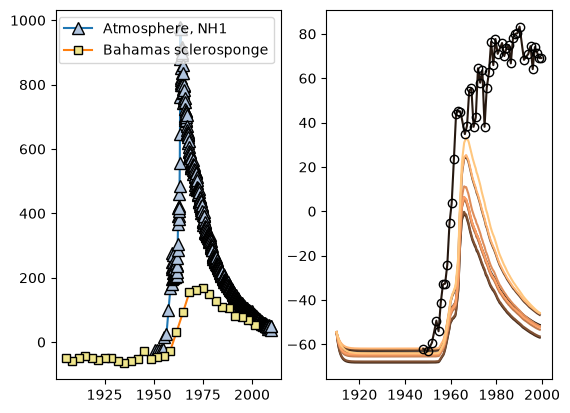

In [3]:
#Run the forward model perturbance 10 times:
#Load the data time series (better to do this outside of the function, because the function will be running 1000 times!)
A = pd.read_csv('NH1.csv')                  #The atmospheric input is the Northern Hemisphere bomb curve. 
S = pd.read_csv('sclerosponge_C14.csv')     #The subtropical input is the sclerosponge record from the western Atlantic Subtropical Underwater
print(type(S))
#Get the Cape Verde data
C_dat = pd.read_csv('CapeVerde_radiocarbon.csv')    #The Cape Verde data from this project
#Add a D14C column to the Cape Verde dataset
C_dat['D14C'] = (C_dat['Fm']-1)*1000
C_dat['sig_D14C'] = 1000*C_dat['sigma_Fm']

fig, ax = plt.subplots(nrows=1, ncols=2)

#Plot inputs:
ax[0].plot(A['year'], A['D14C'], label='Atmosphere, NH1', marker='^', mfc='lightsteelblue', mec='k', markersize=8)
ax[0].plot(S['year'], S['D14C'], label='Bahamas sclerosponge', marker='s', mfc='khaki', mec='k')
ax[0].legend()
color_map = plt.get_cmap('copper')
N = 10
ax[1].set_prop_cycle(color=color_map(np.linspace(0.12, 1, N)))
for k in range(N):
    xes, C_out = Trend_Final(A, S)
    #print(C_out[1:5,:])
    ax[1].plot(xes, C_out, linestyle='-')

#Add Cape Verde data:
ax[1].plot(C_dat['year'], C_dat['D14C'], marker='o', mfc='none', mec='k')
    

In [4]:
col_list = []
for j in np.arange(1000):
    x, Ct = Trend_Final(A, S)
    #print(Ct)
    col_list.append(Ct)






In [5]:
print([col.shape for col in col_list[0:2]])


output_df = pd.DataFrame(np.concatenate(col_list, axis=1))

print(output_df.head())


[(8900, 1), (8900, 1)]
         0          1          2          3          4          5    \
0 -54.448379 -54.461479 -54.466546 -54.449601 -54.460727 -54.480756   
1 -54.496503 -54.522600 -54.532642 -54.498897 -54.521134 -54.560932   
2 -54.544375 -54.583365 -54.598291 -54.547891 -54.581224 -54.640534   
3 -54.591996 -54.643776 -54.663496 -54.596584 -54.640999 -54.719564   
4 -54.639367 -54.703835 -54.728259 -54.644979 -54.700460 -54.798027   

         6          7          8          9    ...        990        991  \
0 -54.443273 -54.448266 -54.451212 -54.451271  ... -54.456224 -54.414363   
1 -54.486342 -54.496292 -54.502151 -54.502238  ... -54.512145 -54.428686   
2 -54.529208 -54.544078 -54.552819 -54.552903  ... -54.567765 -54.442969   
3 -54.571873 -54.591627 -54.603217 -54.603268  ... -54.623085 -54.457211   
4 -54.614337 -54.638939 -54.653346 -54.653335  ... -54.678106 -54.471414   

         992        993        994        995        996        997  \
0 -54.457819 -54.44226

<>:12: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:12: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
C:\Users\brosenheim.FOREST\AppData\Local\Temp\ipykernel_32412\3167085838.py:12: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  ax.set(xlabel='Year', ylabel='$\Delta^{14}C$')


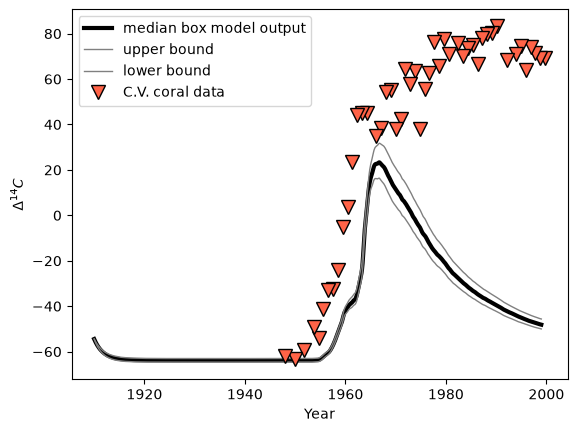

In [6]:
#Calculate percentiles:
med = output_df.quantile(q=0.5, axis=1)     #median (50%)
plus = output_df.quantile(q=0.68, axis=1)   #median plus one standard deviation
minus = output_df.quantile(q=0.32, axis=1)  #median minus one standard deviation

#Plot the results:
fig, ax = plt.subplots(nrows=1, ncols=1)
ax.plot(x, med, 'k', linewidth=3, label='median box model output')
ax.plot(x, plus, color='grey', linewidth=1, label='upper bound')
ax.plot(x, minus, color='grey', linewidth=1, label='lower bound')
ax.plot(C_dat['year'], C_dat['D14C'], marker='v', mec='k', mfc='tomato', linestyle='', markersize=10, label='C.V. coral data')
ax.set(xlabel='Year', ylabel='$\Delta^{14}C$')
ax.legend()